# 03 — EDA on Processed OOC Dataset

This notebook replaces the old EDA that read raw dataset folders directly.

It reads only:

```text
data/processed/ooc_pairs/manifests/*.csv
```

and saves paper-ready figures/tables under:

```text
paper/figures/
paper/tables/
```

Run after `data_setup_updated.ipynb`.


In [1]:
from pathlib import Path
import sys
import os

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()

    for p in [start, *start.parents]:
        if (p / "data").exists() and (p / "src").exists():
            return p

    raise RuntimeError(
        "Could not find repo root. Start Jupyter from E:/eve-rag or place this notebook inside the repo."
    )

ROOT = find_repo_root()
os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Repo root:", ROOT)
print("src exists:", (ROOT / "src").exists())
print("paths.py exists:", (ROOT / "src" / "utils" / "paths.py").exists())

from src.utils.paths import (
    MANIFESTS,
    PROCESSED_IMAGES,
    REPORTS,
    TRAIN_MANIFEST,
    VAL_MANIFEST,
    TEST_MANIFEST,
    VERITE_TEST_MANIFEST,
    MMFAKEBENCH_VAL_MANIFEST,
    MMFAKEBENCH_TEST_MANIFEST,
    ALL_MANIFEST,
    SPLITS,
    DATA,
    RAW,
    PROCESSED,
)

Repo root: E:\eve-rag
src exists: True
paths.py exists: True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

TABLES = ROOT / "paper" / "tables"
FIGURES = ROOT / "paper" / "figures"

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

COL_MATCH = "#2E7D32"
COL_MISMATCH = "#C62828"
COL_NEUTRAL = "#546E7A"
COL_ACCENT = "#1565C0"

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

def savecsv(df, name):
    path = TABLES / f"{name}.csv"
    df.to_csv(path, index=False, encoding="utf-8")
    print(f"Saved: {path}")
    return path

def savefig(fig_or_name, name=None, dpi=200):
    if name is None:
        fig = plt.gcf()
        name = fig_or_name
    else:
        fig = fig_or_name

    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Saved: {path}")
    return path

## 1. Load manifests


In [3]:
def read_manifest(path):
    return pd.read_csv(
        path,
        dtype={
            "pair_id": "string",
            "dataset": "string",
            "split": "string",
            "image_id": "string",
            "image_path": "string",
            "caption": "string",
            "label_name": "string",
        },
        low_memory=False,
    )

train_df = read_manifest(TRAIN_MANIFEST)
val_df = read_manifest(VAL_MANIFEST)
test_df = read_manifest(TEST_MANIFEST)
verite_df = read_manifest(VERITE_TEST_MANIFEST)
mmfake_val_df = read_manifest(MMFAKEBENCH_VAL_MANIFEST)
mmfake_test_df = read_manifest(MMFAKEBENCH_TEST_MANIFEST)
all_df = read_manifest(ALL_MANIFEST)

print("Loaded manifests:")
for name, df in [
    ("train", train_df), ("val", val_df), ("test", test_df),
    ("verite_test", verite_df), ("mmfakebench_val", mmfake_val_df),
    ("mmfakebench_test", mmfake_test_df), ("all", all_df),
]:
    print(f"  {name:<18} {len(df):>8,} rows")


Loaded manifests:
  train                71,072 rows
  val                   7,024 rows
  test                  7,264 rows
  verite_test           1,001 rows
  mmfakebench_val       1,000 rows
  mmfakebench_test     10,000 rows
  all                  97,361 rows


## 2. Dataset summary table


In [4]:
from pathlib import Path

TABLES = ROOT / "paper" / "tables"
FIGURES = ROOT / "paper" / "figures"

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Keep this flexible version because later cells call savefig("name").
def savecsv(df, name):
    path = TABLES / f"{name}.csv"
    df.to_csv(path, index=False, encoding="utf-8")
    print(f"Saved: {path}")
    return path

def savefig(fig_or_name, name=None, dpi=200):
    if name is None:
        fig = plt.gcf()
        name = fig_or_name
    else:
        fig = fig_or_name

    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Saved: {path}")
    return path


In [5]:
summary_rows = []
for name, df in [
    ("NewsCLIPpings train", train_df),
    ("NewsCLIPpings val", val_df),
    ("NewsCLIPpings test", test_df),
    ("VERITE test", verite_df),
    ("MMFakeBench val", mmfake_val_df),
    ("MMFakeBench test", mmfake_test_df),
    ("All", all_df),
]:
    summary_rows.append({
        "dataset_split": name,
        "rows": len(df),
        "label_0_match": int((df["label"] == 0).sum()),
        "label_1_mismatch": int((df["label"] == 1).sum()),
        "has_image_rows": int(df["has_image"].sum()),
        "unique_image_ids": int(df["image_id"].fillna("").replace("", pd.NA).dropna().nunique()),
        "empty_captions": int((df["caption"].fillna("").astype(str).str.len() == 0).sum()),
    })

summary = pd.DataFrame(summary_rows)
savecsv(summary, "dataset_summary")
summary


Saved: E:\eve-rag\paper\tables\dataset_summary.csv


,dataset_split,rows,label_0_match,label_1_mismatch,has_image_rows,unique_image_ids,empty_captions
0,NewsCLIPpings train,71072,35536,35536,0,59876,0
1,NewsCLIPpings val,7024,3512,3512,0,5943,0
2,NewsCLIPpings test,7264,3632,3632,0,6147,0
3,VERITE test,1001,338,663,621,495,0
4,MMFakeBench val,1000,300,700,1000,1000,0
5,MMFakeBench test,10000,3000,7000,10000,10000,0
6,All,97361,46318,51043,11621,83461,0


## 3. Class balance figure


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Consistent plot colors
COL_MATCH = "#2E7D32"      # green
COL_MISMATCH = "#C62828"   # red
COL_NEUTRAL = "#546E7A"    # blue-gray
COL_ACCENT = "#1565C0"     # blue

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

Saved: E:\eve-rag\paper\figures\eda_class_balance_processed.png


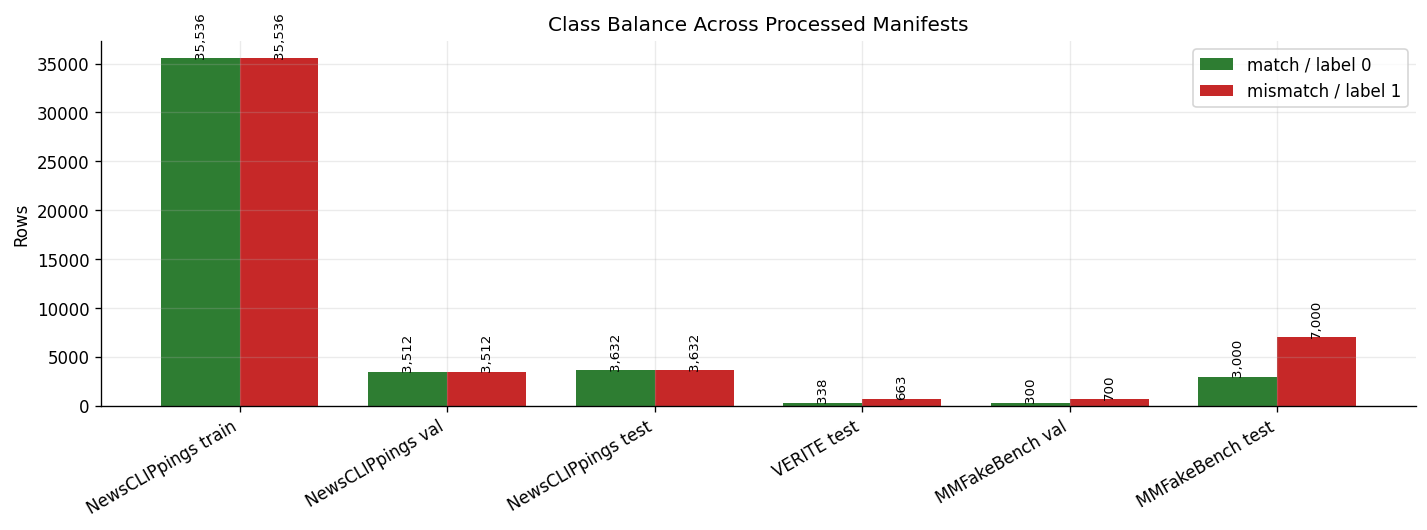

In [7]:
plot_df = summary[summary["dataset_split"] != "All"].copy()
x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - width/2, plot_df["label_0_match"], width, label="match / label 0", color=COL_MATCH)
ax.bar(x + width/2, plot_df["label_1_mismatch"], width, label="mismatch / label 1", color=COL_MISMATCH)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["dataset_split"], rotation=30, ha="right")
ax.set_ylabel("Rows")
ax.set_title("Class Balance Across Processed Manifests")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for i, row in plot_df.iterrows():
    idx = list(plot_df.index).index(i)
    ax.text(idx - width/2, row["label_0_match"], f'{row["label_0_match"]:,}', ha="center", va="bottom", fontsize=8, rotation=90)
    ax.text(idx + width/2, row["label_1_mismatch"], f'{row["label_1_mismatch"]:,}', ha="center", va="bottom", fontsize=8, rotation=90)
plt.tight_layout()
savefig("eda_class_balance_processed")
plt.show()


## 4. Image coverage figure


Saved: E:\eve-rag\paper\figures\eda_image_coverage_processed.png


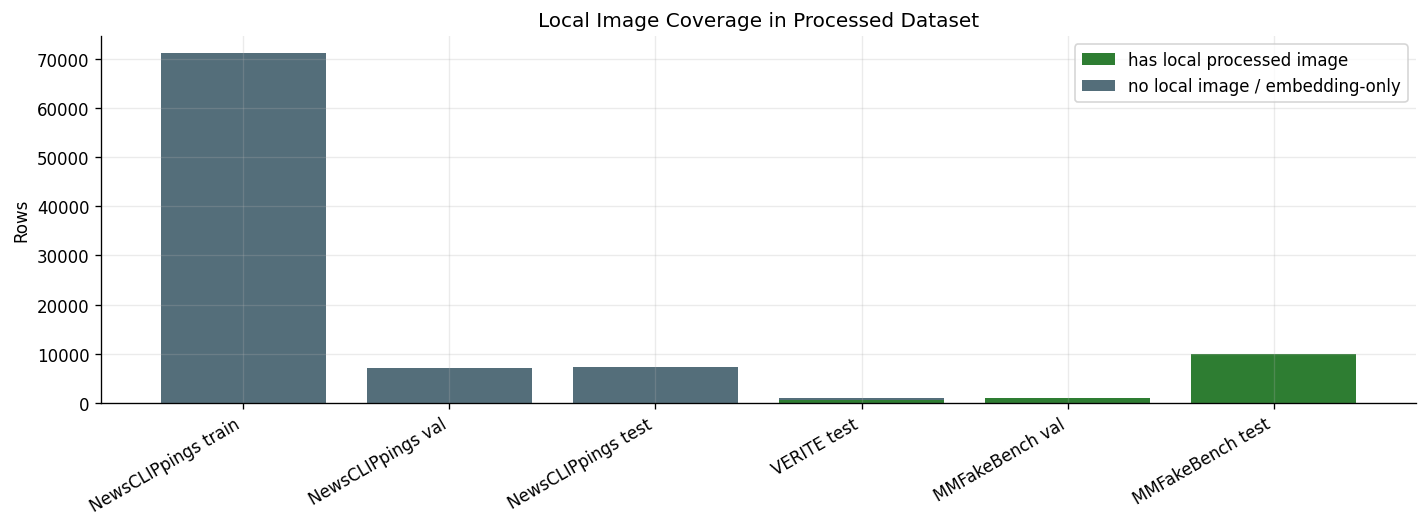

In [8]:
coverage_df = summary[summary["dataset_split"] != "All"].copy()
coverage_df["missing_image_rows"] = coverage_df["rows"] - coverage_df["has_image_rows"]

x = np.arange(len(coverage_df))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x, coverage_df["has_image_rows"], label="has local processed image", color=COL_MATCH)
ax.bar(x, coverage_df["missing_image_rows"], bottom=coverage_df["has_image_rows"], label="no local image / embedding-only", color=COL_NEUTRAL)
ax.set_xticks(x)
ax.set_xticklabels(coverage_df["dataset_split"], rotation=30, ha="right")
ax.set_ylabel("Rows")
ax.set_title("Local Image Coverage in Processed Dataset")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig("eda_image_coverage_processed")
plt.show()


## 5. Caption length distributions


In [9]:
caption_df = all_df.copy()
caption_df["caption_len_chars"] = caption_df["caption"].fillna("").astype(str).str.len()
caption_df["caption_len_words"] = caption_df["caption"].fillna("").astype(str).str.split().map(len)

caption_stats = caption_df.groupby("dataset").agg(
    rows=("pair_id", "count"),
    mean_chars=("caption_len_chars", "mean"),
    median_chars=("caption_len_chars", "median"),
    mean_words=("caption_len_words", "mean"),
    median_words=("caption_len_words", "median"),
).reset_index()
savecsv(caption_stats, "caption_length_stats")
caption_stats


Saved: E:\eve-rag\paper\tables\caption_length_stats.csv


,dataset,rows,mean_chars,median_chars,mean_words,median_words
0,mmfakebench,11000,79.569909,74.0,13.544455,13.0
1,newsclippings,85360,98.046567,95.0,16.645127,16.0
2,verite,1001,125.358641,121.0,20.859141,20.0


Saved: E:\eve-rag\paper\figures\eda_caption_length_distribution.png


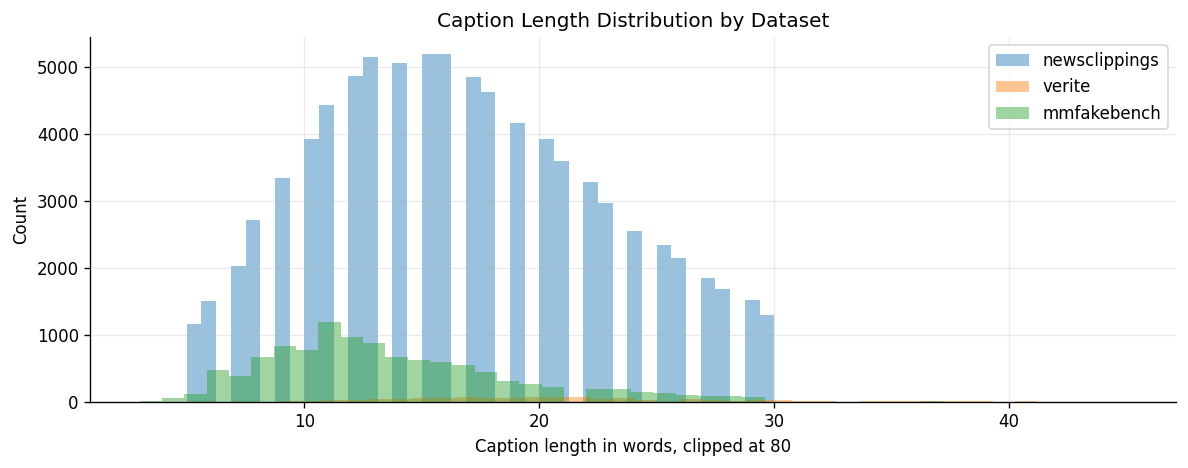

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for dataset in ["newsclippings", "verite", "mmfakebench"]:
    vals = caption_df.loc[caption_df["dataset"] == dataset, "caption_len_words"].clip(upper=80)
    ax.hist(vals, bins=40, alpha=0.45, label=dataset)
ax.set_title("Caption Length Distribution by Dataset")
ax.set_xlabel("Caption length in words, clipped at 80")
ax.set_ylabel("Count")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig("eda_caption_length_distribution")
plt.show()


## 6. VERITE analysis


In [11]:
verite_label = verite_df.groupby(["raw_label", "label", "label_name"]).size().reset_index(name="count")
savecsv(verite_label, "verite_label_distribution")
verite_label


Saved: E:\eve-rag\paper\tables\verite_label_distribution.csv


,raw_label,label,label_name,count
0,miscaptioned,1,mismatch,338
1,out-of-context,1,mismatch,325
2,true,0,match,338


In [12]:
verite_image_summary = pd.DataFrame([
    {"metric": "rows", "value": len(verite_df)},
    {"metric": "rows_with_local_image", "value": int(verite_df["has_image"].sum())},
    {"metric": "unique_image_ids", "value": int(verite_df["image_id"].replace("", pd.NA).dropna().nunique())},
    {"metric": "broken_image_paths", "value": int(((verite_df["has_image"] == 1) & (~verite_df["image_path"].fillna("").map(lambda p: (ROOT / p).exists()))).sum())},
])
savecsv(verite_image_summary, "verite_image_coverage")
verite_image_summary


Saved: E:\eve-rag\paper\tables\verite_image_coverage.csv


,metric,value
0,rows,1001
1,rows_with_local_image,621
2,unique_image_ids,495
3,broken_image_paths,0


## 7. MMFakeBench analysis


In [13]:
mmfake_all = pd.concat([mmfake_val_df, mmfake_test_df], ignore_index=True)
mmfake_labels = mmfake_all.groupby(["split", "label", "label_name"]).size().reset_index(name="count")
savecsv(mmfake_labels, "mmfakebench_label_distribution")
mmfake_labels


Saved: E:\eve-rag\paper\tables\mmfakebench_label_distribution.csv


,split,label,label_name,count
0,test,0,match,3000
1,test,1,mismatch,7000
2,val,0,match,300
3,val,1,mismatch,700


In [14]:
fake_cls = mmfake_all["fake_cls"].fillna("").replace("", "unknown").value_counts().reset_index()
fake_cls.columns = ["fake_cls", "count"]
savecsv(fake_cls, "mmfakebench_fake_cls_distribution")
fake_cls.head(30)


Saved: E:\eve-rag\paper\tables\mmfakebench_fake_cls_distribution.csv


,fake_cls,count
0,original,3300
1,textual_veracity_distortion,3300
2,mismatch,3300
3,visual_veracity_distortion,1100


Saved: E:\eve-rag\paper\figures\eda_mmfakebench_fake_cls_top20.png


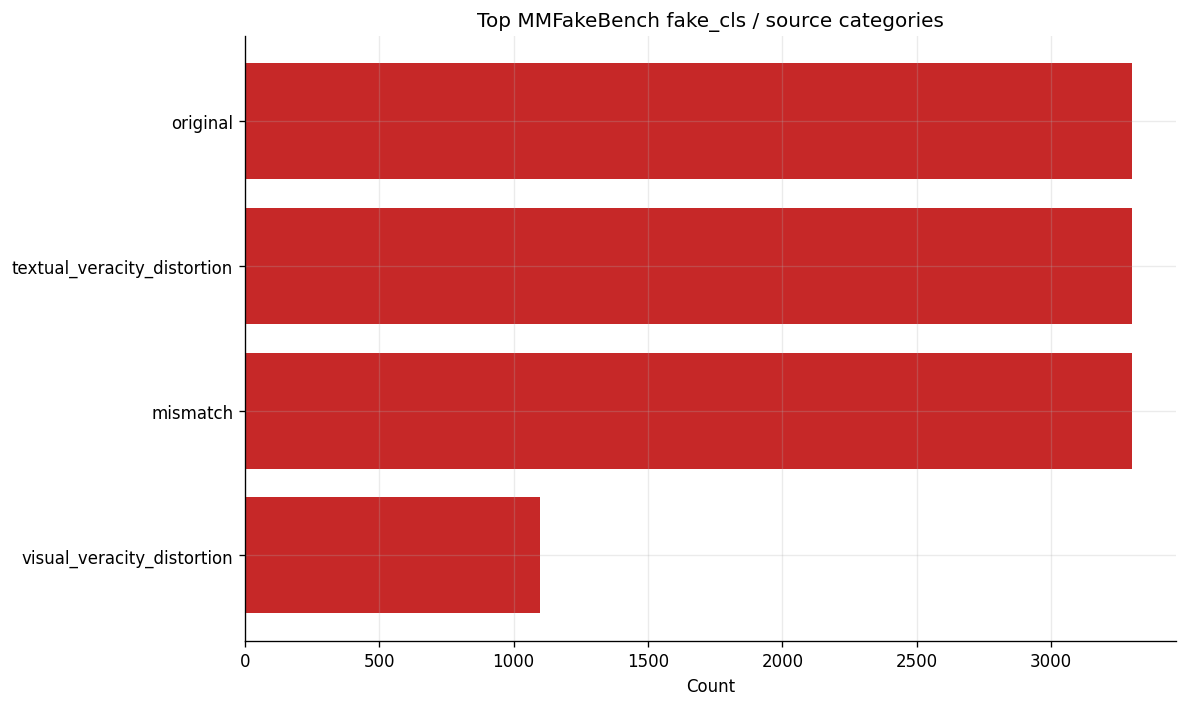

In [15]:
top = fake_cls.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["fake_cls"], top["count"], color=COL_MISMATCH)
ax.set_title("Top MMFakeBench fake_cls / source categories")
ax.set_xlabel("Count")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig("eda_mmfakebench_fake_cls_top20")
plt.show()


## 8. Processed image filename sanity check


In [16]:
flat_images = [p for p in PROCESSED_IMAGES.iterdir() if p.is_file()]
image_sanity = pd.DataFrame({
    "metric": [
        "flat_image_files",
        "manifest_rows_with_image",
        "unique_manifest_image_ids_with_image",
        "broken_image_paths",
    ],
    "value": [
        len(flat_images),
        int(all_df["has_image"].sum()),
        int(all_df.loc[all_df["has_image"] == 1, "image_id"].replace("", pd.NA).dropna().nunique()),
        int(((all_df["has_image"] == 1) & (~all_df["image_path"].fillna("").map(lambda p: (ROOT / p).exists()))).sum()),
    ]
})
savecsv(image_sanity, "processed_image_sanity")
image_sanity


Saved: E:\eve-rag\paper\tables\processed_image_sanity.csv


,metric,value
0,flat_image_files,11495
1,manifest_rows_with_image,11621
2,unique_manifest_image_ids_with_image,11495
3,broken_image_paths,0


## 9. Final EDA summary


In [17]:
print("Processed dataset is ready for notebook migration.")
print("Rows:", len(all_df))
print("Rows with local images:", int(all_df["has_image"].sum()))
print("Flat image files:", len(flat_images))
print("Broken image paths:", image_sanity.loc[image_sanity["metric"] == "broken_image_paths", "value"].iloc[0])
print("Tables written to:", TABLES)
print("Figures written to:", FIGURES)


Processed dataset is ready for notebook migration.
Rows: 97361
Rows with local images: 11621
Flat image files: 11495
Broken image paths: 0
Tables written to: E:\eve-rag\paper\tables
Figures written to: E:\eve-rag\paper\figures
